In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cartopy.crs as ccrs
import cartopy.feature as cf
import cartopy

In [2]:
terciles = np.load('./terciles/terciles_7_Jun_2024.npy')

In [3]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as ticker
from matplotlib.ticker import Formatter, MaxNLocator
from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from cartopy.mpl.geoaxes import GeoAxes
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter

In [4]:
def make_cmap( map_color='bwr', N=11, continuous=True):
	if map_color == 'WindowsCPT':
		colors = [(238, 43, 51), (255, 57, 67),(253, 123, 91),(248, 175, 123),(254, 214, 158),(252, 239, 188),(255, 254, 241),(244, 255,255),(187, 252, 255),(160, 235, 255),(123, 210, 255),(89, 179, 238),(63, 136, 254),(52, 86, 254)]
		colors = [ (colors[i][0] / 255.0, colors[i][1] / 255.0, colors[i][2] / 255.0) for i in range(len(colors))]
		colors.reverse()
		if str(continuous) == "continuous":
			return LinearSegmentedColormap.from_list( "CPT", colors)
		else:
			return LinearSegmentedColormap.from_list( "CPT", colors, N=N)
	else:
		map_color = 'bwr' #override user input
		if str(continuous) == 'continuous':
			return plt.get_cmap(map_color)
		else:
			return plt.get_cmap(map_color, N)
def make_cmap_blue(x):
	colors = [(255, 255,255),
	(187, 252, 255),
	(160, 235, 255),
	(123, 210, 255),
	(89, 179, 238),
	(63, 136, 254),
	(52, 86, 254)]
	colors = [ (colors[i][0] / 255.0, colors[i][1] / 255.0, colors[i][2] / 255.0) for i in range(len(colors))]
	#colors.reverse()
	return LinearSegmentedColormap.from_list( "matlab_clone", colors, N=x)
def discrete_cmap(N, base_cmap=None):
	"""Create an N-bin discrete colormap from the specified input map"""
	# Note that if base_cmap is a string or None, you can simply do
	#    return plt.cm.get_cmap(base_cmap, N)
	# The following works for string, None, or a colormap instance:
	base = plt.cm.get_cmap(base_cmap)
	color_list = base(np.linspace(0, 1, N))
	cmap_name = base.name + str(N)
	#base.set_bad(color='white')
	#return base.from_list(cmap_name, color_list, N)
	return LinearSegmentedColormap.from_list(cmap_name, color_list, N) #perceptually uniform colormaps

In [5]:
terciles.shape

(32, 31, 1, 3)

In [6]:
terciles_squeezed = np.squeeze(terciles, axis=2)
terciles_squeezed.shape

(32, 31, 3)

In [7]:
p_an =100*terciles_squeezed[:,:,2]
p_n =100*terciles_squeezed[:,:,1]
p_bn =100*terciles_squeezed[:,:,0]

In [8]:
import numpy as np
import cv2

# Step 1: Create a mask of NaN values
nan_mask_an = np.isnan(p_an)
nan_mask_n = np.isnan(p_n)
nan_mask_bn = np.isnan(p_bn)

# Step 2: Replace NaN values with 0 (or another value that works best for your data)
matrix_no_nan_an = np.where(nan_mask_an, 0, p_an)
matrix_no_nan_n = np.where(nan_mask_n, 0, p_n)
matrix_no_nan_bn = np.where(nan_mask_bn, 0, p_bn)

# Step 3: Apply Gaussian smoothing
# Define the kernel size (for example 3x3) and sigma
smoothed_matrix_an = cv2.GaussianBlur(matrix_no_nan_an, (3, 3), sigmaX=1)
smoothed_matrix_n = cv2.GaussianBlur(matrix_no_nan_n, (3, 3), sigmaX=1)
smoothed_matrix_bn = cv2.GaussianBlur(matrix_no_nan_bn, (3, 3), sigmaX=1)

# Step 4: Restore the NaN values in the smoothed matrix
smoothed_matrix_an[nan_mask_an] = np.nan
smoothed_matrix_n[nan_mask_n] = np.nan
smoothed_matrix_bn[nan_mask_bn] = np.nan

# # Resulting smoothed matrix with NaN values restored
# print(smoothed_matrix)

In [9]:
overall_matrix = np.zeros((32,31,3))
overall_matrix[:,:,0] = smoothed_matrix_an
overall_matrix[:,:,1] = smoothed_matrix_n
overall_matrix[:,:,2] = smoothed_matrix_bn

overall_matrix.shape

(32, 31, 3)

In [10]:
totals = np.nansum(overall_matrix, axis=2)

In [11]:
overall_matrix[:,:,0] /= totals
overall_matrix[:,:,1] /= totals
overall_matrix[:,:,2] /= totals

In [12]:
# Initialize arrays to store the result
result1 = np.full(overall_matrix[:,:,0].shape, np.nan)
result2 = np.full(overall_matrix[:,:,1].shape, np.nan)
result3 = np.full(overall_matrix[:,:,2].shape, np.nan)

# Find the maximum value for each index across the three arrays
max_values = np.maximum(np.maximum(overall_matrix[:,:,0], overall_matrix[:,:,1]), overall_matrix[:,:,2])

# Use boolean indexing to retain the values from the arrays that are the maximum
result1[overall_matrix[:,:,0] == max_values] = overall_matrix[:,:,0][overall_matrix[:,:,0] == max_values]
result2[overall_matrix[:,:,1] == max_values] = overall_matrix[:,:,1][overall_matrix[:,:,1] == max_values]
result3[overall_matrix[:,:,2] == max_values] = overall_matrix[:,:,2][overall_matrix[:,:,2] == max_values]

In [13]:
max_values.shape

(32, 31)

In [14]:
import utils_forecast as utils

In [15]:
download = False

In [16]:
xf = utils.get_forecast(download)

In [17]:
xf

<xarray.DataArray 'prcp' (T: 1, M: 31, Y: 32, X: 31)> Size: 246kB
[30752 values with dtype=float64]
Coordinates:
    S        (T) datetime64[ns] 8B 2024-06-07
  * M        (M) float32 124B 0.0 1.0 2.0 3.0 4.0 ... 26.0 27.0 28.0 29.0 30.0
  * X        (X) float32 124B 68.0 69.0 70.0 71.0 72.0 ... 95.0 96.0 97.0 98.0
  * Y        (Y) float32 128B 7.0 8.0 9.0 10.0 11.0 ... 34.0 35.0 36.0 37.0 38.0
  * T        (T) datetime64[ns] 8B 2024-06-28
Attributes:
    pointwidth:          0.0
    expires:             1727568000
    standard_name:       precipitation_flux
    level_type:          surface
    long_name:           Total Precipitation
    file_missing_value:  -9999.0
    history:             Averaged over L[14.0 days, 28.0 days] minimum 0.0% d...
    units:               mm/day

In [18]:
lats, longs = xf['Y'].values,xf['X'].values

In [19]:
lats

array([ 7.,  8.,  9., 10., 11., 12., 13., 14., 15., 16., 17., 18., 19.,
       20., 21., 22., 23., 24., 25., 26., 27., 28., 29., 30., 31., 32.,
       33., 34., 35., 36., 37., 38.], dtype=float32)

In [20]:
lats, longs = xf['Y'].values,xf['X'].values

current_cmap = plt.get_cmap('BuGn')
#current_cmap.set_bad(color='white')

current_cmap_copper = plt.get_cmap('YlOrRd', 9)
current_cmap_binary = plt.get_cmap('Greys', 4)
current_cmap_ylgn = make_cmap_blue(9)

In [21]:
xf = utils.get_forecast(download)

averaged_data = xf.mean('M').values

# averaged_data = np.squeeze(averaged_data, axis=0)

averaged_data = averaged_data*86400

In [22]:
def plot(ax, west, east, south, north):
    """
    Add geographical boundaries from the shapes folder to the plot.

    Parameters:
        - ax (matplotlib.axes._subplots.AxesSubplot): Axes object to add geographical boundaries.
        - west, east, south, north (float): Geographic bounds for the region of interest.
    """
    for shape_name in 'indian_borders', 'sd_boundary':
        reader = cartopy.io.shapereader.Reader(f'shapes/{shape_name}')
        ax.add_geometries(reader.geometries(), ccrs.PlateCarree(), facecolor='none')

NameError: name 'day' is not defined

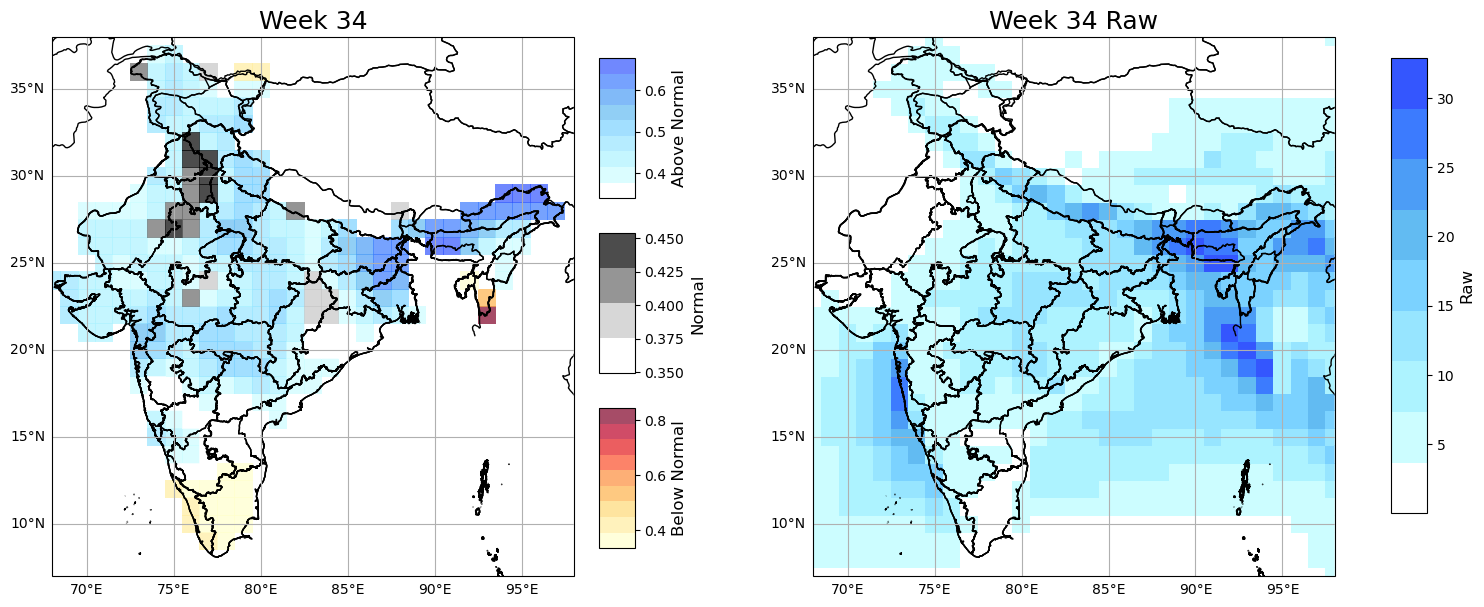

In [23]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors

# Longitude and Latitude grid settings
west, east, south, north = 68, 98, 7, 38
fig = plt.figure(figsize=(18, 7))

# Generate a meshgrid for pcolor
lon = np.linspace(west, east, result1.shape[1])
lat = np.linspace(south, north, result1.shape[0])
lon_grid, lat_grid = np.meshgrid(lon, lat)

# Plot for RPSS
ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
ax1.set_extent([west, east, south, north], crs=ccrs.PlateCarree())

# Plot the three results using pcolor
rpss_image1 = ax1.pcolor(lon_grid, lat_grid, result1, cmap=current_cmap_ylgn, alpha=0.7)
rpss_image2 = ax1.pcolor(lon_grid, lat_grid, result2, cmap=current_cmap_binary, alpha=0.7)
rpss_image3 = ax1.pcolor(lon_grid, lat_grid, result3, cmap=current_cmap_copper, alpha=0.7)

ax2 = fig.add_subplot(1, 2, 2, projection=ccrs.PlateCarree())
ax2.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
image_4 = ax2.pcolor(lon_grid, lat_grid, np.squeeze(averaged_data, axis=0), cmap=current_cmap_ylgn)
ax2.set_title(f"Week 34 Raw", fontsize=18)
ax2.add_feature(cf.BORDERS)
ax2.add_feature(cf.STATES)
gl = ax2.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

# Add title, features, and gridlines
ax1.set_title(f"Week 34", fontsize=18)
ax1.add_feature(cf.BORDERS)
ax1.add_feature(cf.STATES)
gl = ax1.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

# Adjust the position of the colorbars manually
# Colorbar for result1 (Above Normal)
cbar_ax1 = fig.add_axes([0.46, 0.65, 0.02, 0.2])  # Adjust the [left, bottom, width, height]
cbar1 = fig.colorbar(rpss_image1, cax=cbar_ax1)
cbar1.set_label('Above Normal', fontsize=12)

# Colorbar for result2 (Normal)
cbar_ax2 = fig.add_axes([0.46, 0.4, 0.02, 0.2])  # Adjust the [left, bottom, width, height]
cbar2 = fig.colorbar(rpss_image2, cax=cbar_ax2)
cbar2.set_label('Normal', fontsize=12)

# Colorbar for result3 (Below Normal)
cbar_ax3 = fig.add_axes([0.46, 0.15, 0.02, 0.2])  # Adjust the [left, bottom, width, height]
cbar3 = fig.colorbar(rpss_image3, cax=cbar_ax3)
cbar3.set_label('Below Normal', fontsize=12)

cbar_ax4 = fig.add_axes([0.9, 0.2, 0.02, 0.65])  # Adjust the [left, bottom, width, height]
cbar4 = fig.colorbar(image_4, cax=cbar_ax4)
cbar4.set_label('Raw', fontsize=12)

for ax in [ax1, ax2]:
    plot(ax, west, east, south, north)
    
# Save and show the plot
plt.savefig(f'./plots/Week34_forecasts_{day}_{month}_{year}.jpg', bbox_inches='tight', dpi=600)

plt.show()

In [29]:
dates = [7,14,21,28,5,12,19,26,2,9,16,23,30,6,13,20,27]
months = ['Jun', 'Jun', 'Jun', 'Jun', 'Jul', 'Jul', 'Jul', 'Jul', 'Aug', 'Aug','Aug','Aug','Aug','Sep', 'Sep', 'Sep', 'Sep']
year = 2024

month_mapping = {
    'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'Jun': 6,
    'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12
}

In [30]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors

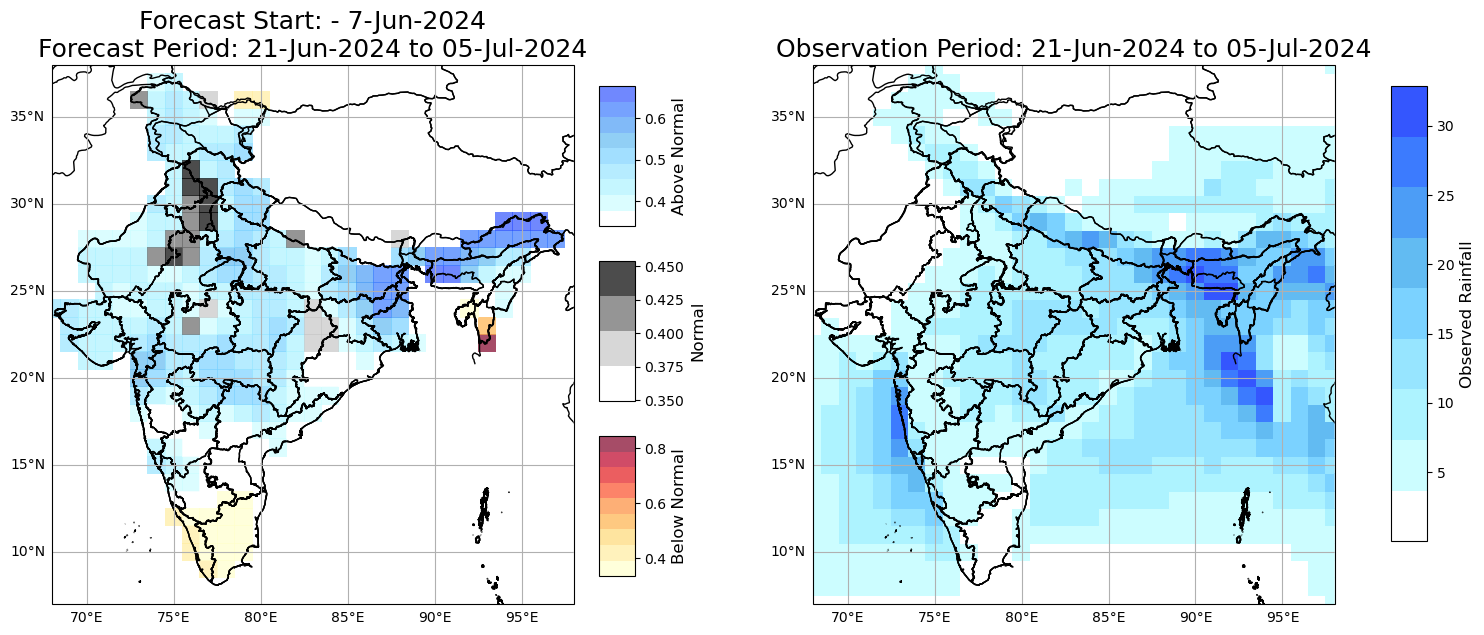

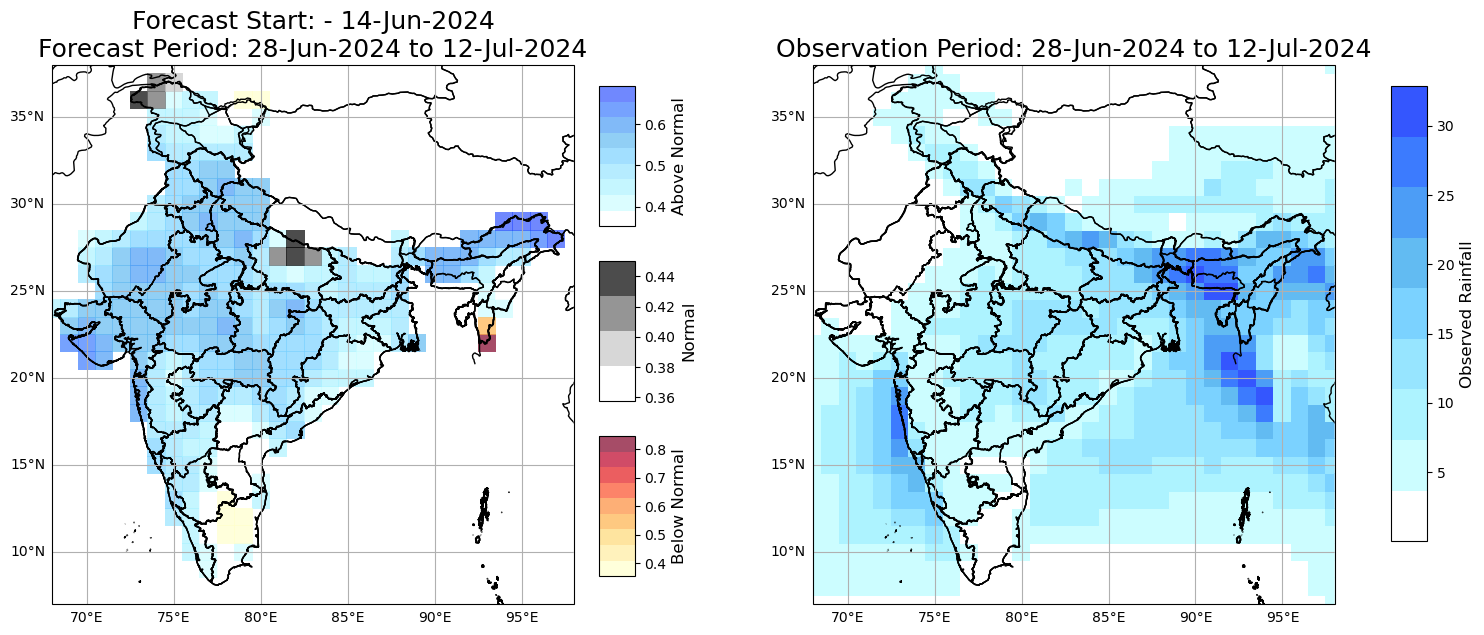

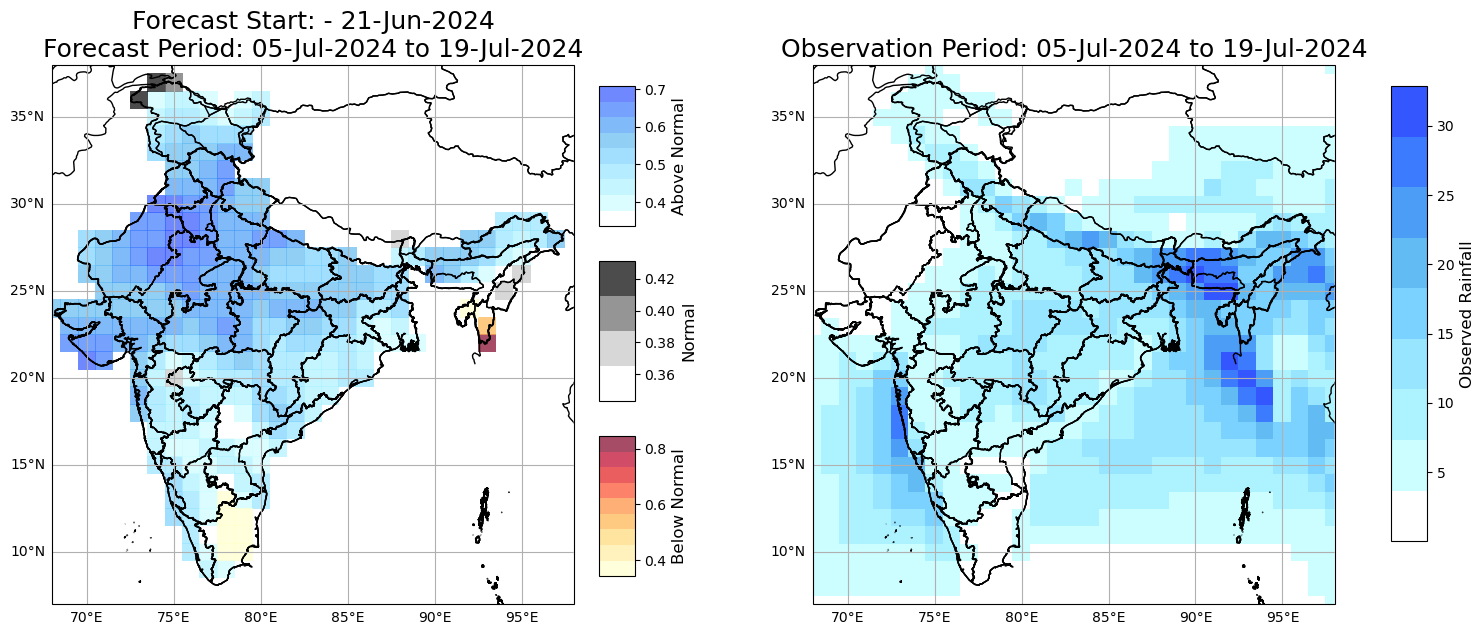

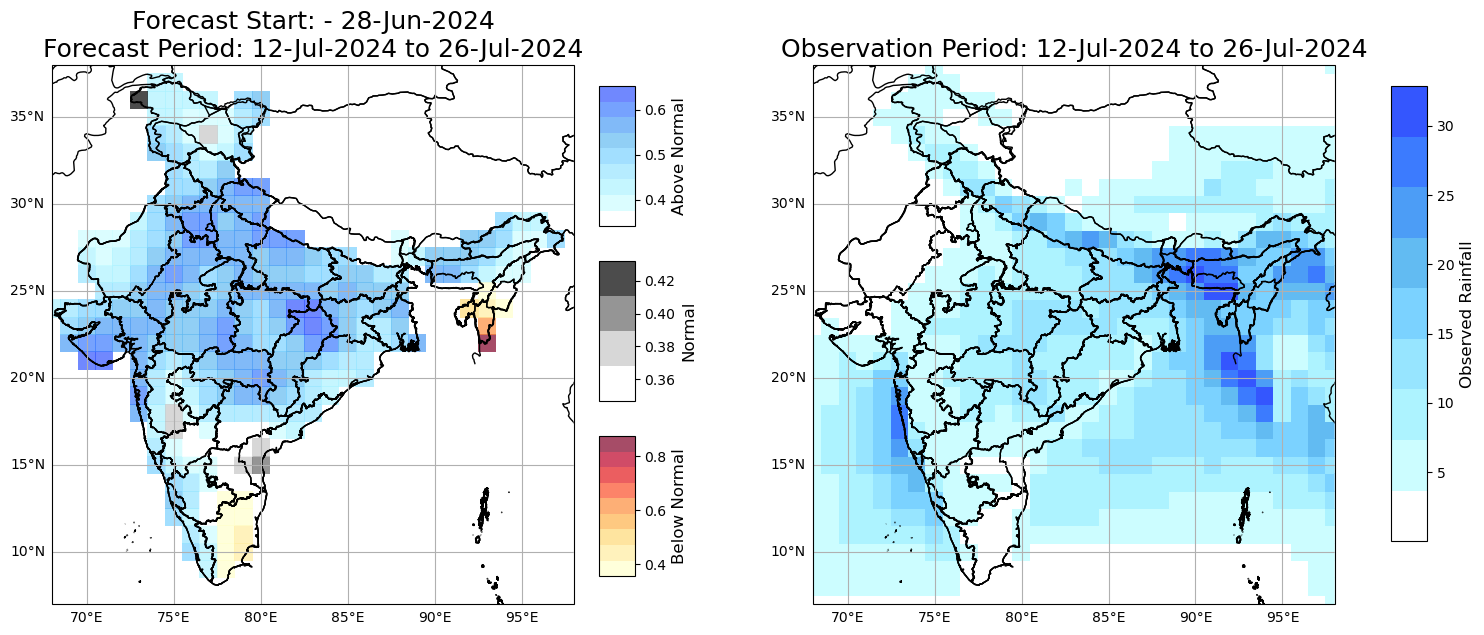

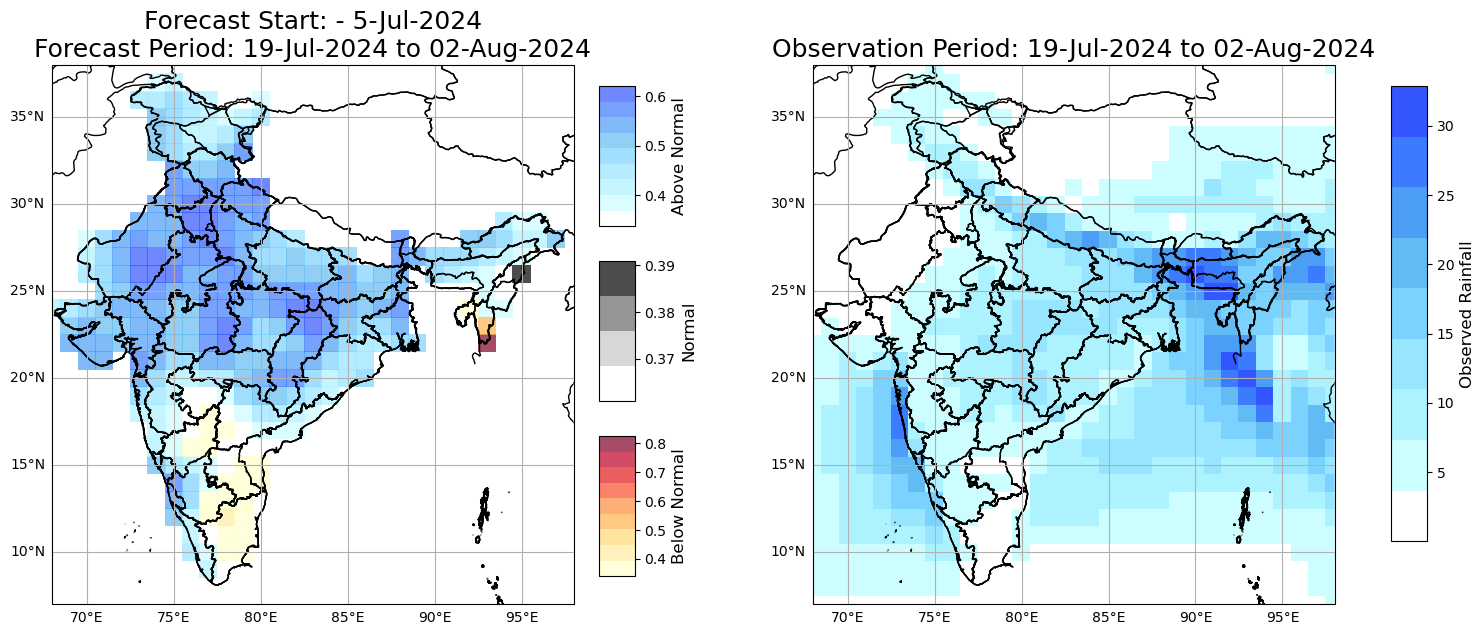

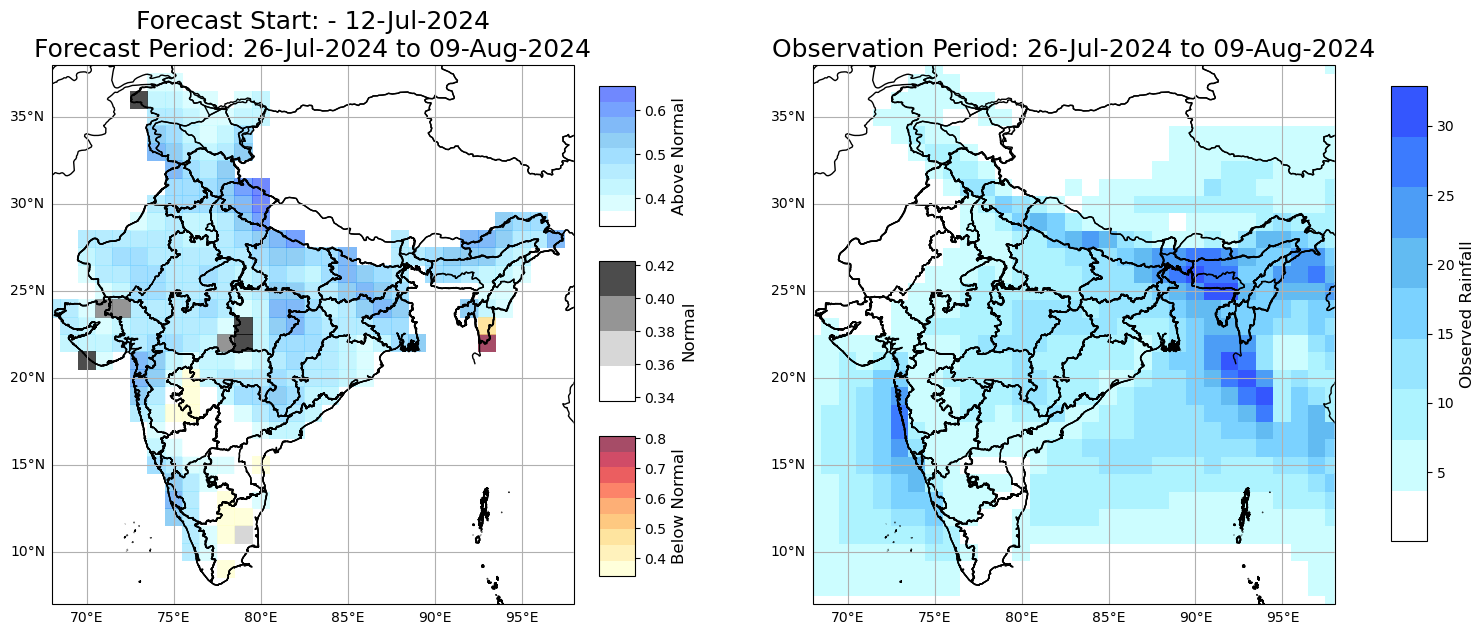

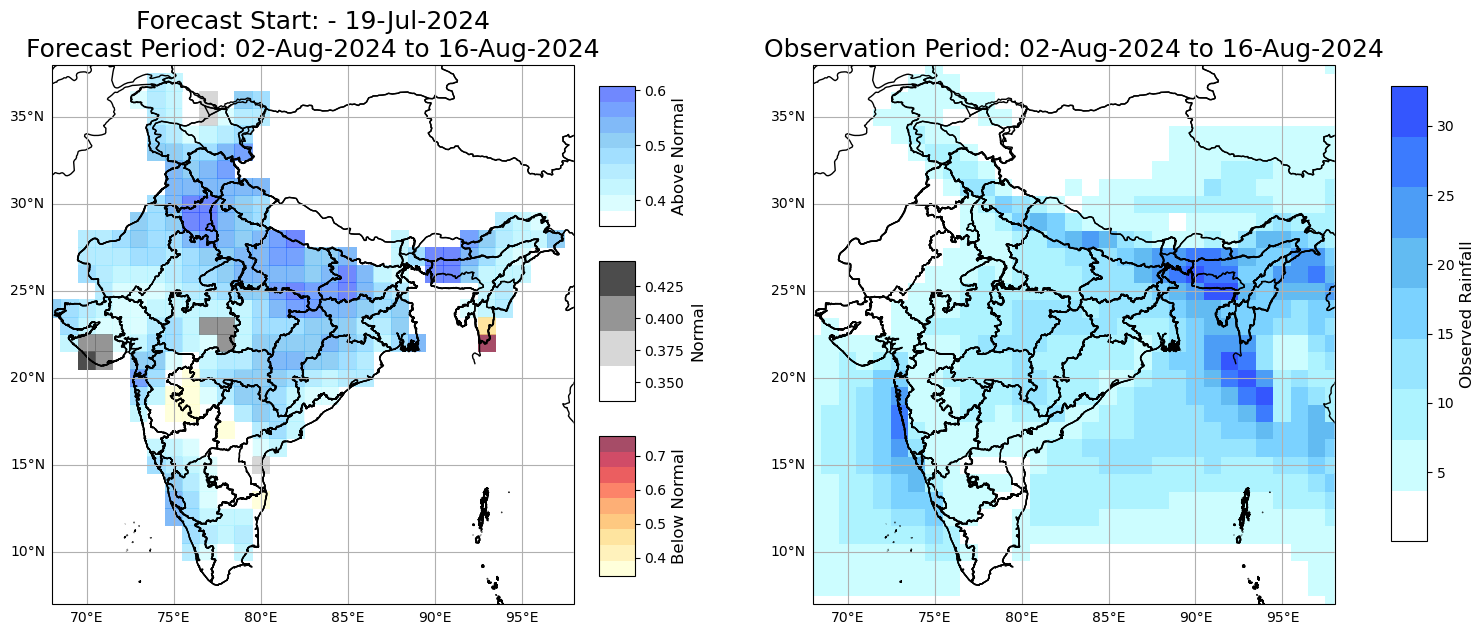

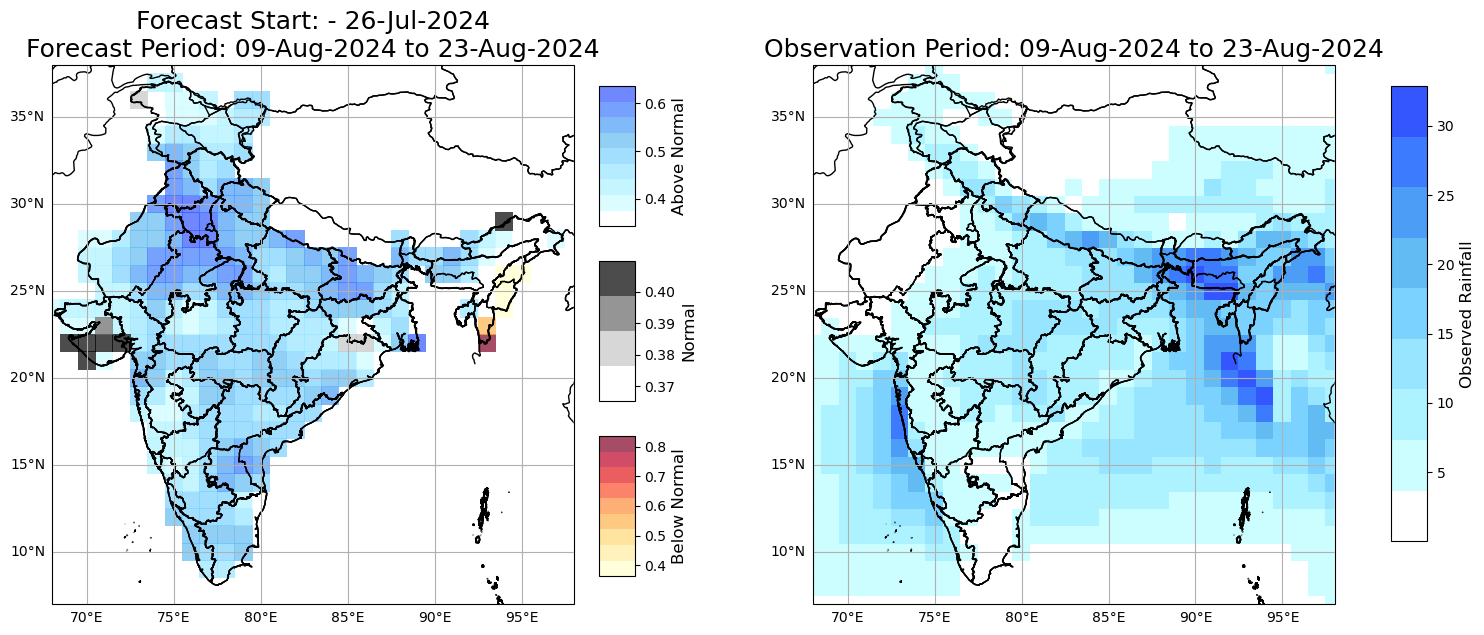

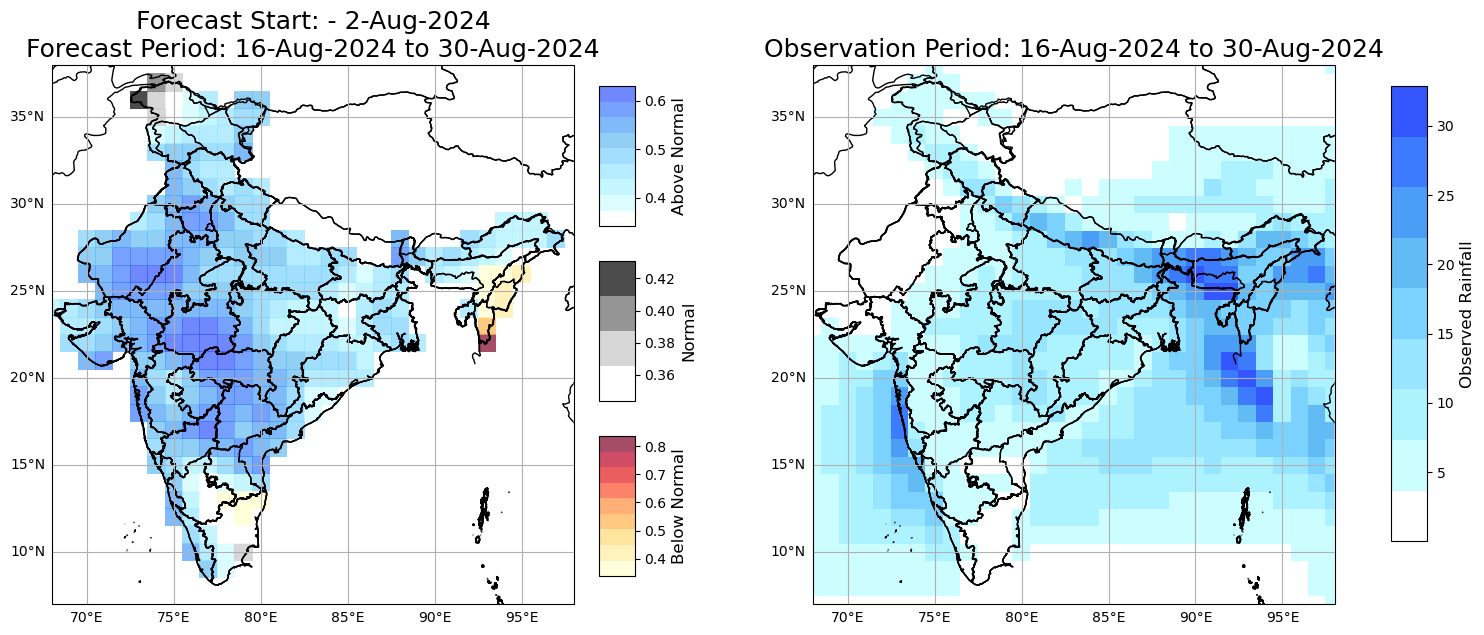

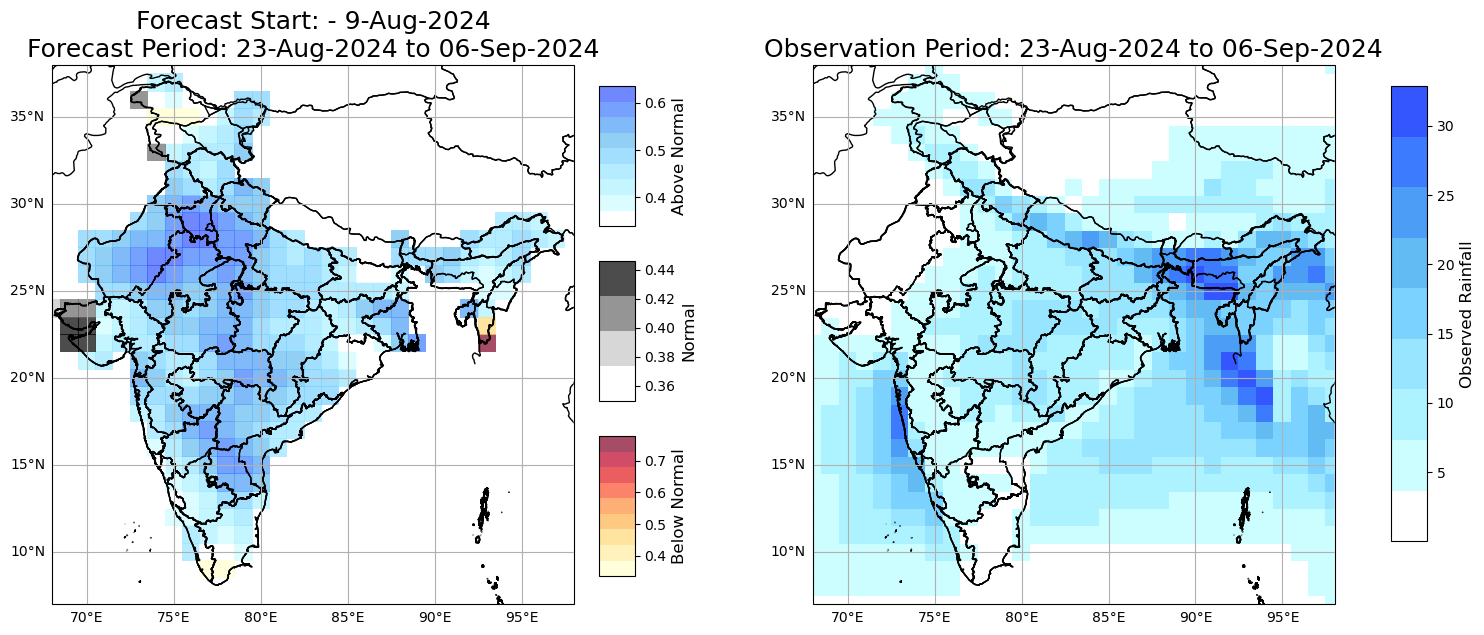

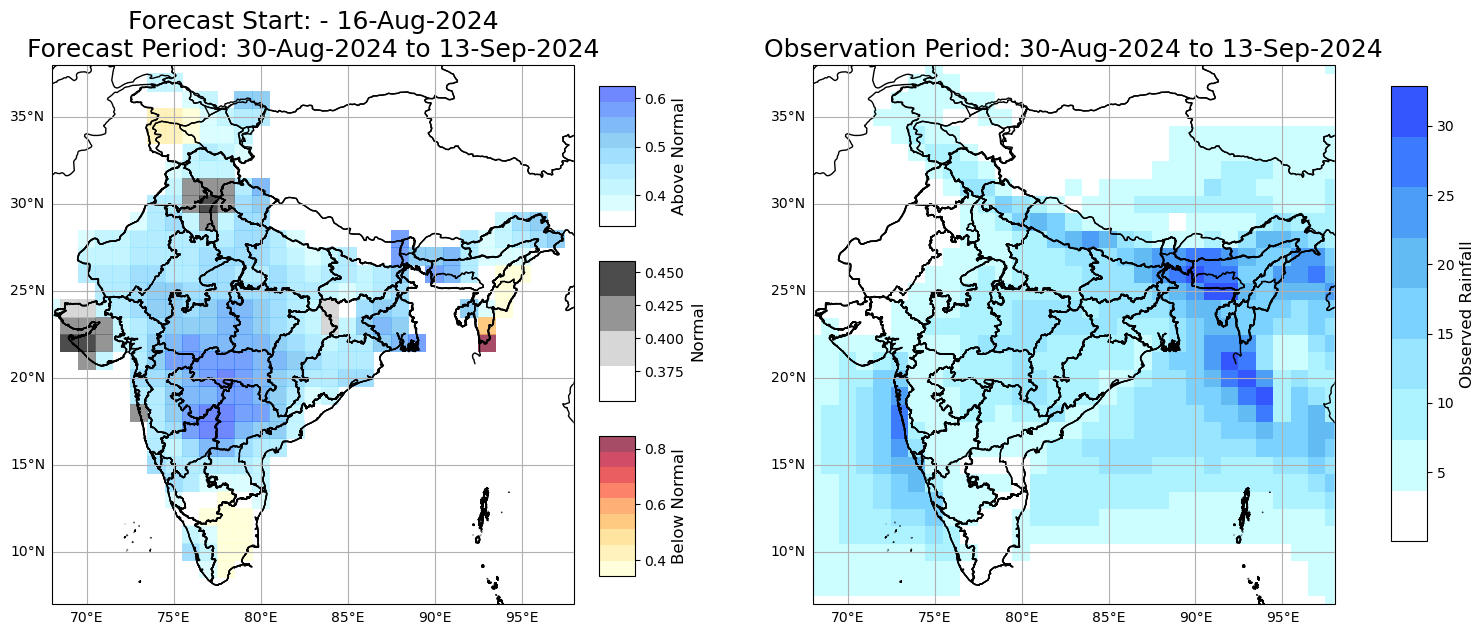

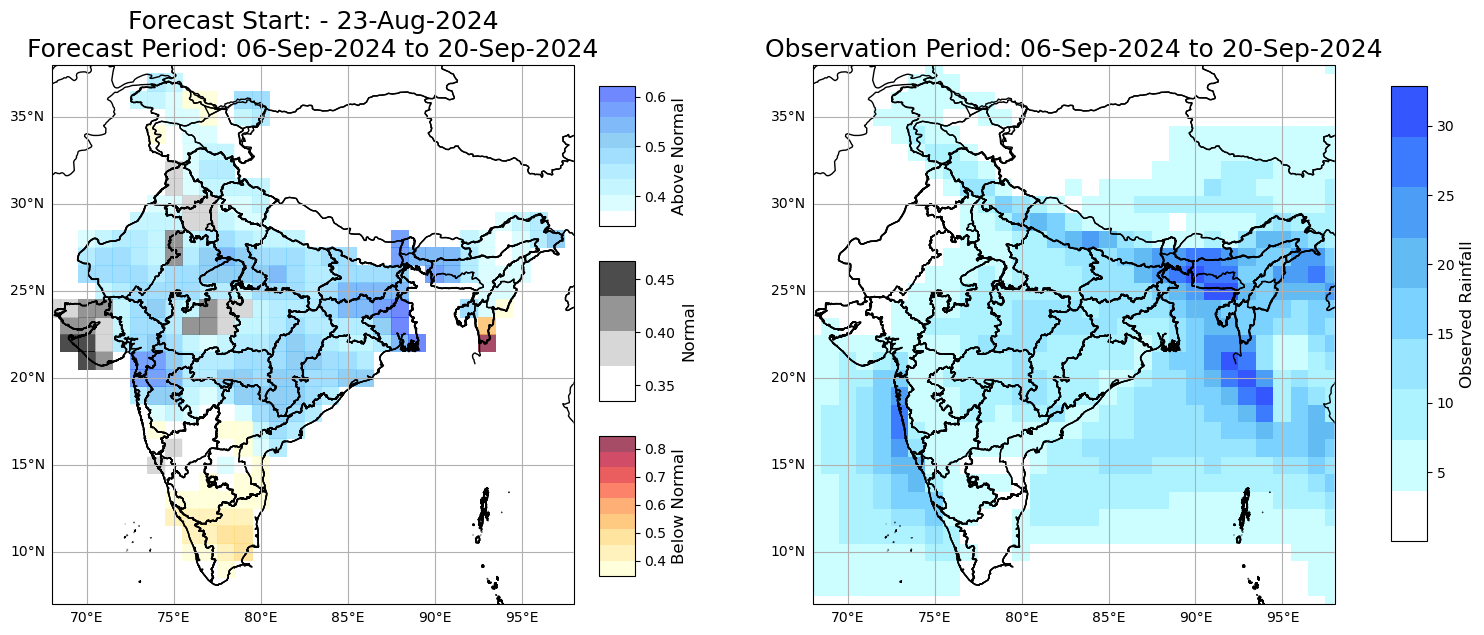

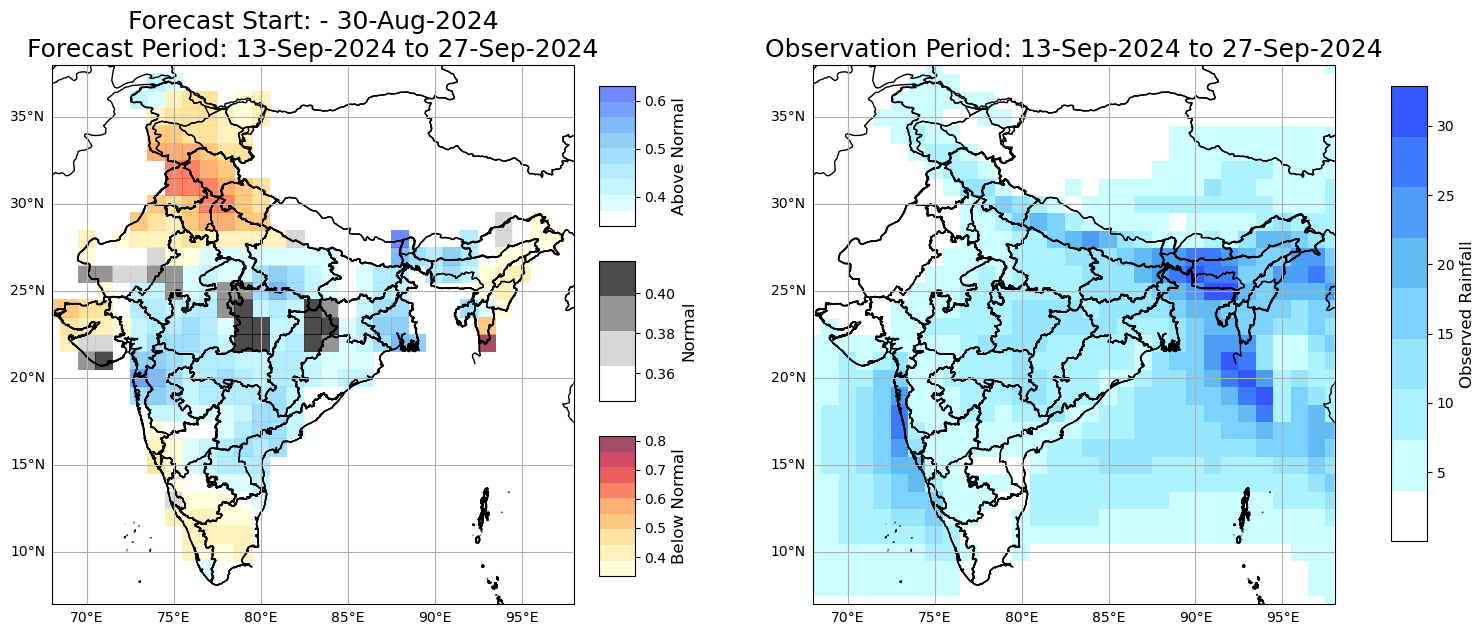

File terciles_6_Sep_2024.npy does not exist.
File terciles_13_Sep_2024.npy does not exist.


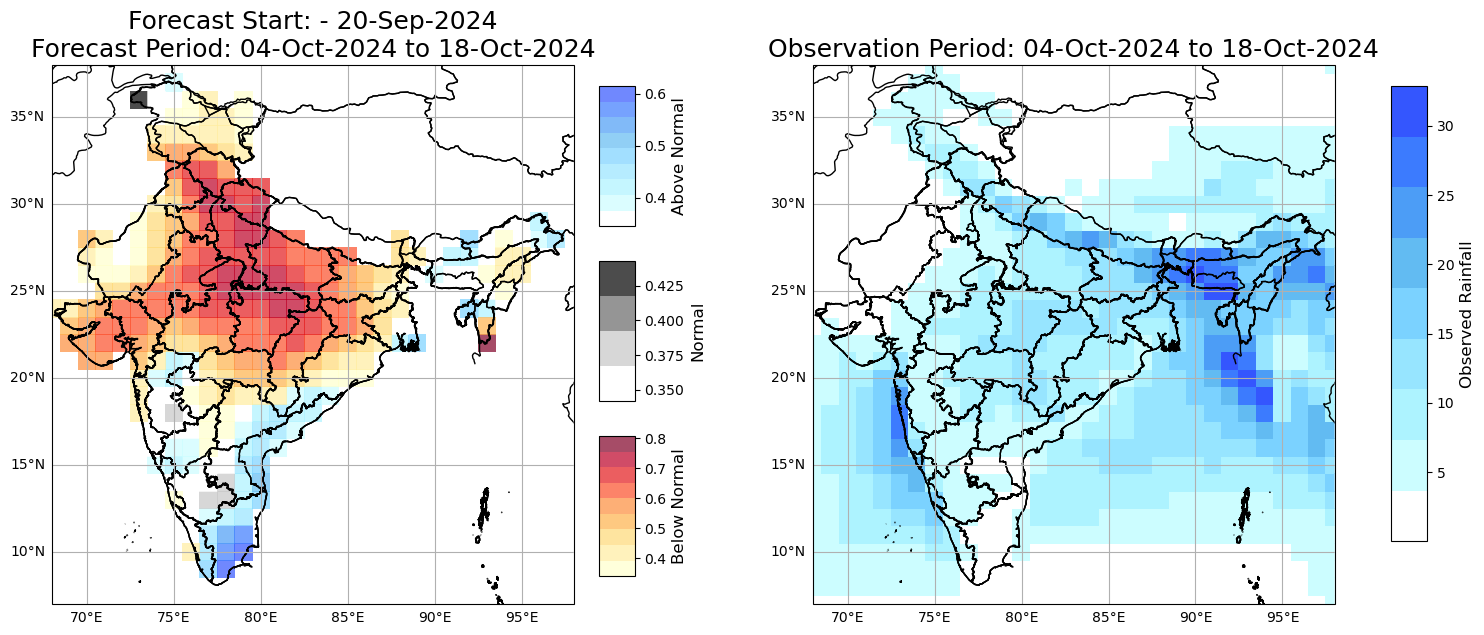

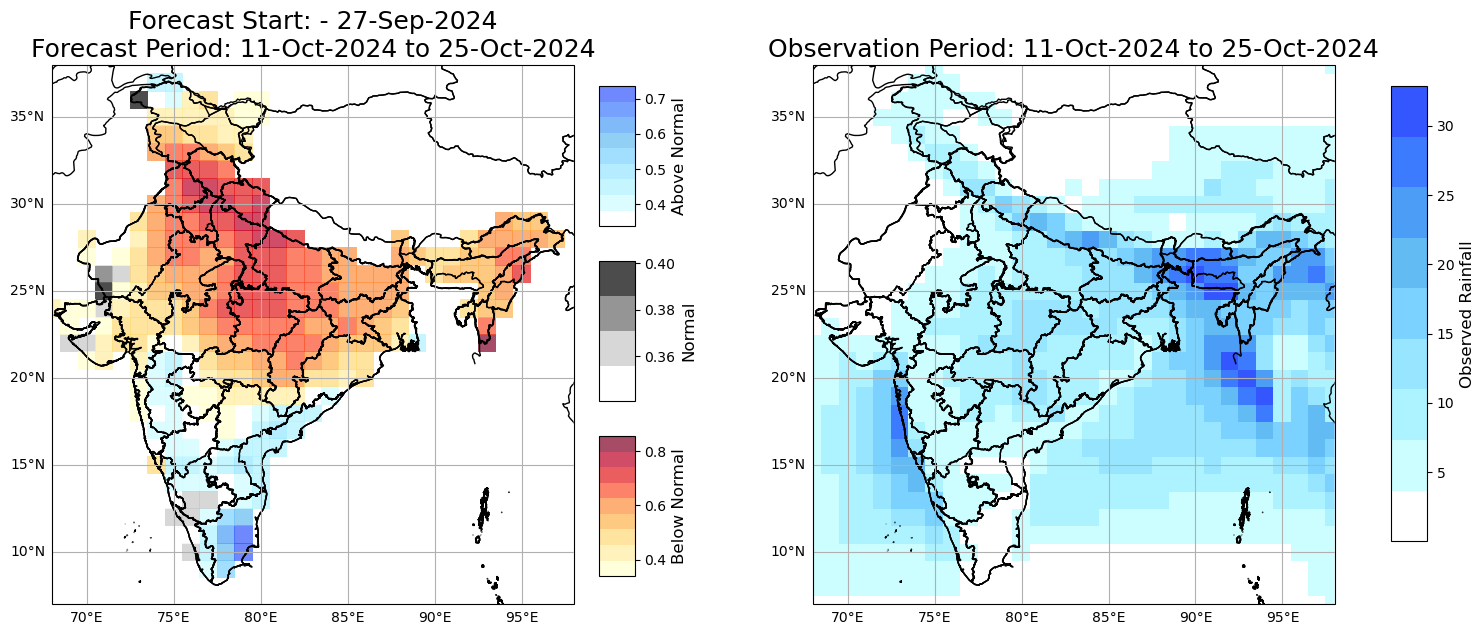

In [38]:
for i in range(17):
    
    try:
        terciles = np.load(f'./terciles/terciles_{dates[i]}_{months[i]}_{year}.npy')
        terciles_squeezed = np.squeeze(terciles, axis=2)
        p_an =100*terciles_squeezed[:,:,2]
        p_n =100*terciles_squeezed[:,:,1]
        p_bn =100*terciles_squeezed[:,:,0]
        # Step 1: Create a mask of NaN values
        nan_mask_an = np.isnan(p_an)
        nan_mask_n = np.isnan(p_n)
        nan_mask_bn = np.isnan(p_bn)

        # Step 2: Replace NaN values with 0 (or another value that works best for your data)
        matrix_no_nan_an = np.where(nan_mask_an, 0, p_an)
        matrix_no_nan_n = np.where(nan_mask_n, 0, p_n)
        matrix_no_nan_bn = np.where(nan_mask_bn, 0, p_bn)

        # Step 3: Apply Gaussian smoothing
        # Define the kernel size (for example 3x3) and sigma
        smoothed_matrix_an = cv2.GaussianBlur(matrix_no_nan_an, (3, 3), sigmaX=1)
        smoothed_matrix_n = cv2.GaussianBlur(matrix_no_nan_n, (3, 3), sigmaX=1)
        smoothed_matrix_bn = cv2.GaussianBlur(matrix_no_nan_bn, (3, 3), sigmaX=1)

        # Step 4: Restore the NaN values in the smoothed matrix
        smoothed_matrix_an[nan_mask_an] = np.nan
        smoothed_matrix_n[nan_mask_n] = np.nan
        smoothed_matrix_bn[nan_mask_bn] = np.nan

        overall_matrix = np.zeros((32,31,3))
        overall_matrix[:,:,0] = smoothed_matrix_an
        overall_matrix[:,:,1] = smoothed_matrix_n
        overall_matrix[:,:,2] = smoothed_matrix_bn

        overall_matrix.shape

        totals = np.nansum(overall_matrix, axis=2)

        overall_matrix[:,:,0] /= totals
        overall_matrix[:,:,1] /= totals
        overall_matrix[:,:,2] /= totals

        # Initialize arrays to store the result
        result1 = np.full(overall_matrix[:,:,0].shape, np.nan)
        result2 = np.full(overall_matrix[:,:,1].shape, np.nan)
        result3 = np.full(overall_matrix[:,:,2].shape, np.nan)

        # Find the maximum value for each index across the three arrays
        max_values = np.maximum(np.maximum(overall_matrix[:,:,0], overall_matrix[:,:,1]), overall_matrix[:,:,2])

        # Use boolean indexing to retain the values from the arrays that are the maximum
        result1[overall_matrix[:,:,0] == max_values] = overall_matrix[:,:,0][overall_matrix[:,:,0] == max_values]
        result2[overall_matrix[:,:,1] == max_values] = overall_matrix[:,:,1][overall_matrix[:,:,1] == max_values]
        result3[overall_matrix[:,:,2] == max_values] = overall_matrix[:,:,2][overall_matrix[:,:,2] == max_values]

        # Longitude and Latitude grid settings
        west, east, south, north = 68, 98, 7, 38
        fig = plt.figure(figsize=(18, 7))

        # Generate a meshgrid for pcolor
        lon = np.linspace(west, east, result1.shape[1])
        lat = np.linspace(south, north, result1.shape[0])
        lon_grid, lat_grid = np.meshgrid(lon, lat)
        
        from datetime import datetime, timedelta

        # Calculate the forecast period (14-28 days ahead)
        month_number = month_mapping[months[i]]
        start_date = datetime(year, month_number, dates[i])
        forecast_start = start_date + timedelta(days=14)
        forecast_end = start_date + timedelta(days=28)

        # Format the forecast period as "dd-MMM-yyyy"
        forecast_start_str = forecast_start.strftime("%d-%b-%Y")
        forecast_end_str = forecast_end.strftime("%d-%b-%Y")

        # Plot for RPSS
        ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
        ax1.set_extent([west, east, south, north], crs=ccrs.PlateCarree())

        # Plot the three results using pcolor
        rpss_image1 = ax1.pcolor(lon_grid, lat_grid, result1, cmap=current_cmap_ylgn, alpha=0.7)
        rpss_image2 = ax1.pcolor(lon_grid, lat_grid, result2, cmap=current_cmap_binary, alpha=0.7)
        rpss_image3 = ax1.pcolor(lon_grid, lat_grid, result3, cmap=current_cmap_copper, alpha=0.7)

        ax2 = fig.add_subplot(1, 2, 2, projection=ccrs.PlateCarree())
        ax2.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
        image_4 = ax2.pcolor(lon_grid, lat_grid, np.squeeze(averaged_data, axis=0), cmap=current_cmap_ylgn)
        ax2.set_title(f"Observation Period: {forecast_start_str} to {forecast_end_str}", fontsize=18)
        ax2.add_feature(cf.BORDERS)
        ax2.add_feature(cf.STATES)
        gl = ax2.gridlines(draw_labels=True)
        gl.top_labels = False
        gl.right_labels = False

        # Add title, features, and gridlines
        ax1.set_title(f"Forecast Start: - {dates[i]}-{months[i]}-{year}\nForecast Period: {forecast_start_str} to {forecast_end_str}", fontsize=18)

        ax1.add_feature(cf.BORDERS)
        ax1.add_feature(cf.STATES)
        gl = ax1.gridlines(draw_labels=True)
        gl.top_labels = False
        gl.right_labels = False

        # Adjust the position of the colorbars manually
        # Colorbar for result1 (Above Normal)
        cbar_ax1 = fig.add_axes([0.46, 0.65, 0.02, 0.2])  # Adjust the [left, bottom, width, height]
        cbar1 = fig.colorbar(rpss_image1, cax=cbar_ax1)
        cbar1.set_label('Above Normal', fontsize=12)

        # Colorbar for result2 (Normal)
        cbar_ax2 = fig.add_axes([0.46, 0.4, 0.02, 0.2])  # Adjust the [left, bottom, width, height]
        cbar2 = fig.colorbar(rpss_image2, cax=cbar_ax2)
        cbar2.set_label('Normal', fontsize=12)

        # Colorbar for result3 (Below Normal)
        cbar_ax3 = fig.add_axes([0.46, 0.15, 0.02, 0.2])  # Adjust the [left, bottom, width, height]
        cbar3 = fig.colorbar(rpss_image3, cax=cbar_ax3)
        cbar3.set_label('Below Normal', fontsize=12)

        cbar_ax4 = fig.add_axes([0.9, 0.2, 0.02, 0.65])  # Adjust the [left, bottom, width, height]
        cbar4 = fig.colorbar(image_4, cax=cbar_ax4)
        cbar4.set_label('Observed Rainfall', fontsize=12)

        for ax in [ax1, ax2]:
            plot(ax, west, east, south, north)

        # Save and show the plot
        plt.savefig(f'./new_plots/Week34_forecasts_{dates[i]}_{months[i]}_{year}.jpg', bbox_inches='tight', dpi=600)

        plt.show()
    except:
        print(f"File terciles_{dates[i]}_{months[i]}_{year}.npy does not exist.")

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cf
import cartopy.io.shapereader

def plot_rpss_rps(rpss_1, rpss_2, rpss_3, rpss_4, rpss_5, rpss_6, rpss_7, rpss_8, rpss_9, 
                  title=None, week=None, save=False, vmin=-0.2, vmax=0.2):
    """
    Plot the RPSS, RPS Forecast, and RPS Climatologic maps for a specific region.

    Parameters:
        - rpss (numpy.ndarray): An array containing the RPSS data to be plotted.
        - rps_fc (numpy.ndarray): An array containing the RPS forecast data to be plotted.
        - rps_clim (numpy.ndarray): An array containing the RPS climatologic data to be plotted.
        - title (string): Plot title
        - week (int): One of 1, 2 or 34
        - save (boolean): False by default, change to True if you want to save the plot

    This function plots three side-by-side maps: one for RPSS, one for RPS based on forecast, 
    and one for RPS based on climatology. The plots are displayed with specific color maps and bounds.

    """
    # Define the geographical boundaries
    west, east, south, north = 68, 98, 7, 38
    fig = plt.figure(figsize=(20,20))

    # Plot for RPSS
    ax1 = fig.add_subplot(3, 3, 1, projection=ccrs.PlateCarree())
    ax1.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
    rpss_image1 = ax1.imshow(np.flip(rpss_1, axis=0), vmin=vmin, vmax=vmax, cmap='bwr', extent=[west, east, south, north])
    ax1.set_title(f"BSS - BN - Week 1")
    ax1.add_feature(cf.BORDERS)
    ax1.add_feature(cf.STATES)
    gl = ax1.gridlines(draw_labels=True)
    gl.top_labels = False
    gl.right_labels = False
    plt.colorbar(rpss_image1, ax=ax1, fraction=0.035, pad=0.04)

    ax2 = fig.add_subplot(3, 3, 2, projection=ccrs.PlateCarree())
    ax2.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
    rpss_image2 = ax2.imshow(np.flip(rpss_2, axis=0), vmin=vmin, vmax=vmax, cmap='bwr', extent=[west, east, south, north])
    ax2.set_title(f"BSS - BN - Week 2")
    ax2.add_feature(cf.BORDERS)
    ax2.add_feature(cf.STATES)
    gl = ax2.gridlines(draw_labels=True)
    gl.top_labels = False
    gl.right_labels = False
    plt.colorbar(rpss_image2, ax=ax2, fraction=0.035, pad=0.04)
    
    ax3 = fig.add_subplot(3, 3, 3, projection=ccrs.PlateCarree())
    ax3.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
    rpss_image3 = ax3.imshow(np.flip(rpss_3, axis=0), vmin=vmin, vmax=vmax, cmap='bwr', extent=[west, east, south, north])
    ax3.set_title(f"BSS - BN - Weeks 3&4")
    ax3.add_feature(cf.BORDERS)
    ax3.add_feature(cf.STATES)
    gl = ax3.gridlines(draw_labels=True)
    gl.top_labels = False
    gl.right_labels = False
    plt.colorbar(rpss_image3, ax=ax3, fraction=0.035, pad=0.04)
    
    ax4 = fig.add_subplot(3, 3, 4, projection=ccrs.PlateCarree())
    ax4.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
    rpss_image4 = ax4.imshow(np.flip(rpss_4, axis=0), vmin=vmin, vmax=vmax, cmap='bwr', extent=[west, east, south, north])
    ax4.set_title(f"BSS - N - Week 1")
    ax4.add_feature(cf.BORDERS)
    ax4.add_feature(cf.STATES)
    gl = ax4.gridlines(draw_labels=True)
    gl.top_labels = False
    gl.right_labels = False
    plt.colorbar(rpss_image4, ax=ax4, fraction=0.035, pad=0.04)
    
    ax5 = fig.add_subplot(3, 3, 5, projection=ccrs.PlateCarree())
    ax5.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
    rpss_image5 = ax5.imshow(np.flip(rpss_5, axis=0), vmin=vmin, vmax=vmax, cmap='bwr', extent=[west, east, south, north])
    ax5.set_title(f"BSS - N - Week 2")
    ax5.add_feature(cf.BORDERS)
    ax5.add_feature(cf.STATES)
    gl = ax5.gridlines(draw_labels=True)
    gl.top_labels = False
    gl.right_labels = False
    plt.colorbar(rpss_image5, ax=ax5, fraction=0.035, pad=0.04)
    
    ax6 = fig.add_subplot(3, 3, 6, projection=ccrs.PlateCarree())
    ax6.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
    rpss_image6 = ax6.imshow(np.flip(rpss_6, axis=0), vmin=vmin, vmax=vmax, cmap='bwr', extent=[west, east, south, north])
    ax6.set_title(f"BSS - N - Weeks 3&4")
    ax6.add_feature(cf.BORDERS)
    ax6.add_feature(cf.STATES)
    gl = ax6.gridlines(draw_labels=True)
    gl.top_labels = False
    gl.right_labels = False
    plt.colorbar(rpss_image6, ax=ax6, fraction=0.035, pad=0.04)
    
    ax7 = fig.add_subplot(3, 3, 7, projection=ccrs.PlateCarree())
    ax7.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
    rpss_image7 = ax7.imshow(np.flip(rpss_7, axis=0), vmin=vmin, vmax=vmax, cmap='bwr', extent=[west, east, south, north])
    ax7.set_title(f"BSS - AN - Week 1")
    ax7.add_feature(cf.BORDERS)
    ax7.add_feature(cf.STATES)
    gl = ax7.gridlines(draw_labels=True)
    gl.top_labels = False
    gl.right_labels = False
    plt.colorbar(rpss_image7, ax=ax7, fraction=0.035, pad=0.04)
    
    ax8 = fig.add_subplot(3, 3, 8, projection=ccrs.PlateCarree())
    ax8.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
    rpss_image8 = ax8.imshow(np.flip(rpss_8, axis=0), vmin=vmin, vmax=vmax, cmap='bwr', extent=[west, east, south, north])
    ax8.set_title(f"BSS - AN - Week 2")
    ax8.add_feature(cf.BORDERS)
    ax8.add_feature(cf.STATES)
    gl = ax8.gridlines(draw_labels=True)
    gl.top_labels = False
    gl.right_labels = False
    plt.colorbar(rpss_image8, ax=ax8, fraction=0.035, pad=0.04)
    
    ax9 = fig.add_subplot(3, 3, 9, projection=ccrs.PlateCarree())
    ax9.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
    rpss_image9 = ax9.imshow(np.flip(rpss_9, axis=0), vmin=vmin, vmax=vmax, cmap='bwr', extent=[west, east, south, north])
    ax9.set_title(f"BSS - AN - Weeks 3&4")
    ax9.add_feature(cf.BORDERS)
    ax9.add_feature(cf.STATES)
    gl = ax9.gridlines(draw_labels=True)
    gl.top_labels = False
    gl.right_labels = False
    plt.colorbar(rpss_image9, ax=ax9, fraction=0.035, pad=0.04)

    # Call the plot function to add shapes from the shapes folder
    for ax in [ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9]:
        plot(ax, west, east, south, north)

    plt.tight_layout()
    fig.suptitle(title)
    
    if save:
        plt.savefig(f'{title}.jpg', dpi=600)
    
    plt.show()

def plot(ax, west, east, south, north):
    """
    Add geographical boundaries from the shapes folder to the plot.

    Parameters:
        - ax (matplotlib.axes._subplots.AxesSubplot): Axes object to add geographical boundaries.
        - west, east, south, north (float): Geographic bounds for the region of interest.
    """
    for shape_name in 'indian_borders', 'sd_boundary':
        reader = cartopy.io.shapereader.Reader(f'shapes/{shape_name}')
        ax.add_geometries(reader.geometries(), ccrs.PlateCarree(), facecolor='none')

In [22]:
bss_1_bn = np.load('./bss/bss_mat_week_1_bn.npy')
bss_1_n = np.load('./bss/bss_mat_week_1_n.npy')
bss_1_an = np.load('./bss/bss_mat_week_1_an.npy')
                  
bss_2_bn = np.load('./bss/bss_mat_week_2_bn.npy')
bss_2_n = np.load('./bss/bss_mat_week_2_n.npy')
bss_2_an = np.load('./bss/bss_mat_week_2_an.npy')

bss_34_bn = np.load('./bss/bss_mat_week_34_bn.npy')
bss_34_n = np.load('./bss/bss_mat_week_34_n.npy')
bss_34_an = np.load('./bss/bss_mat_week_34_an.npy')

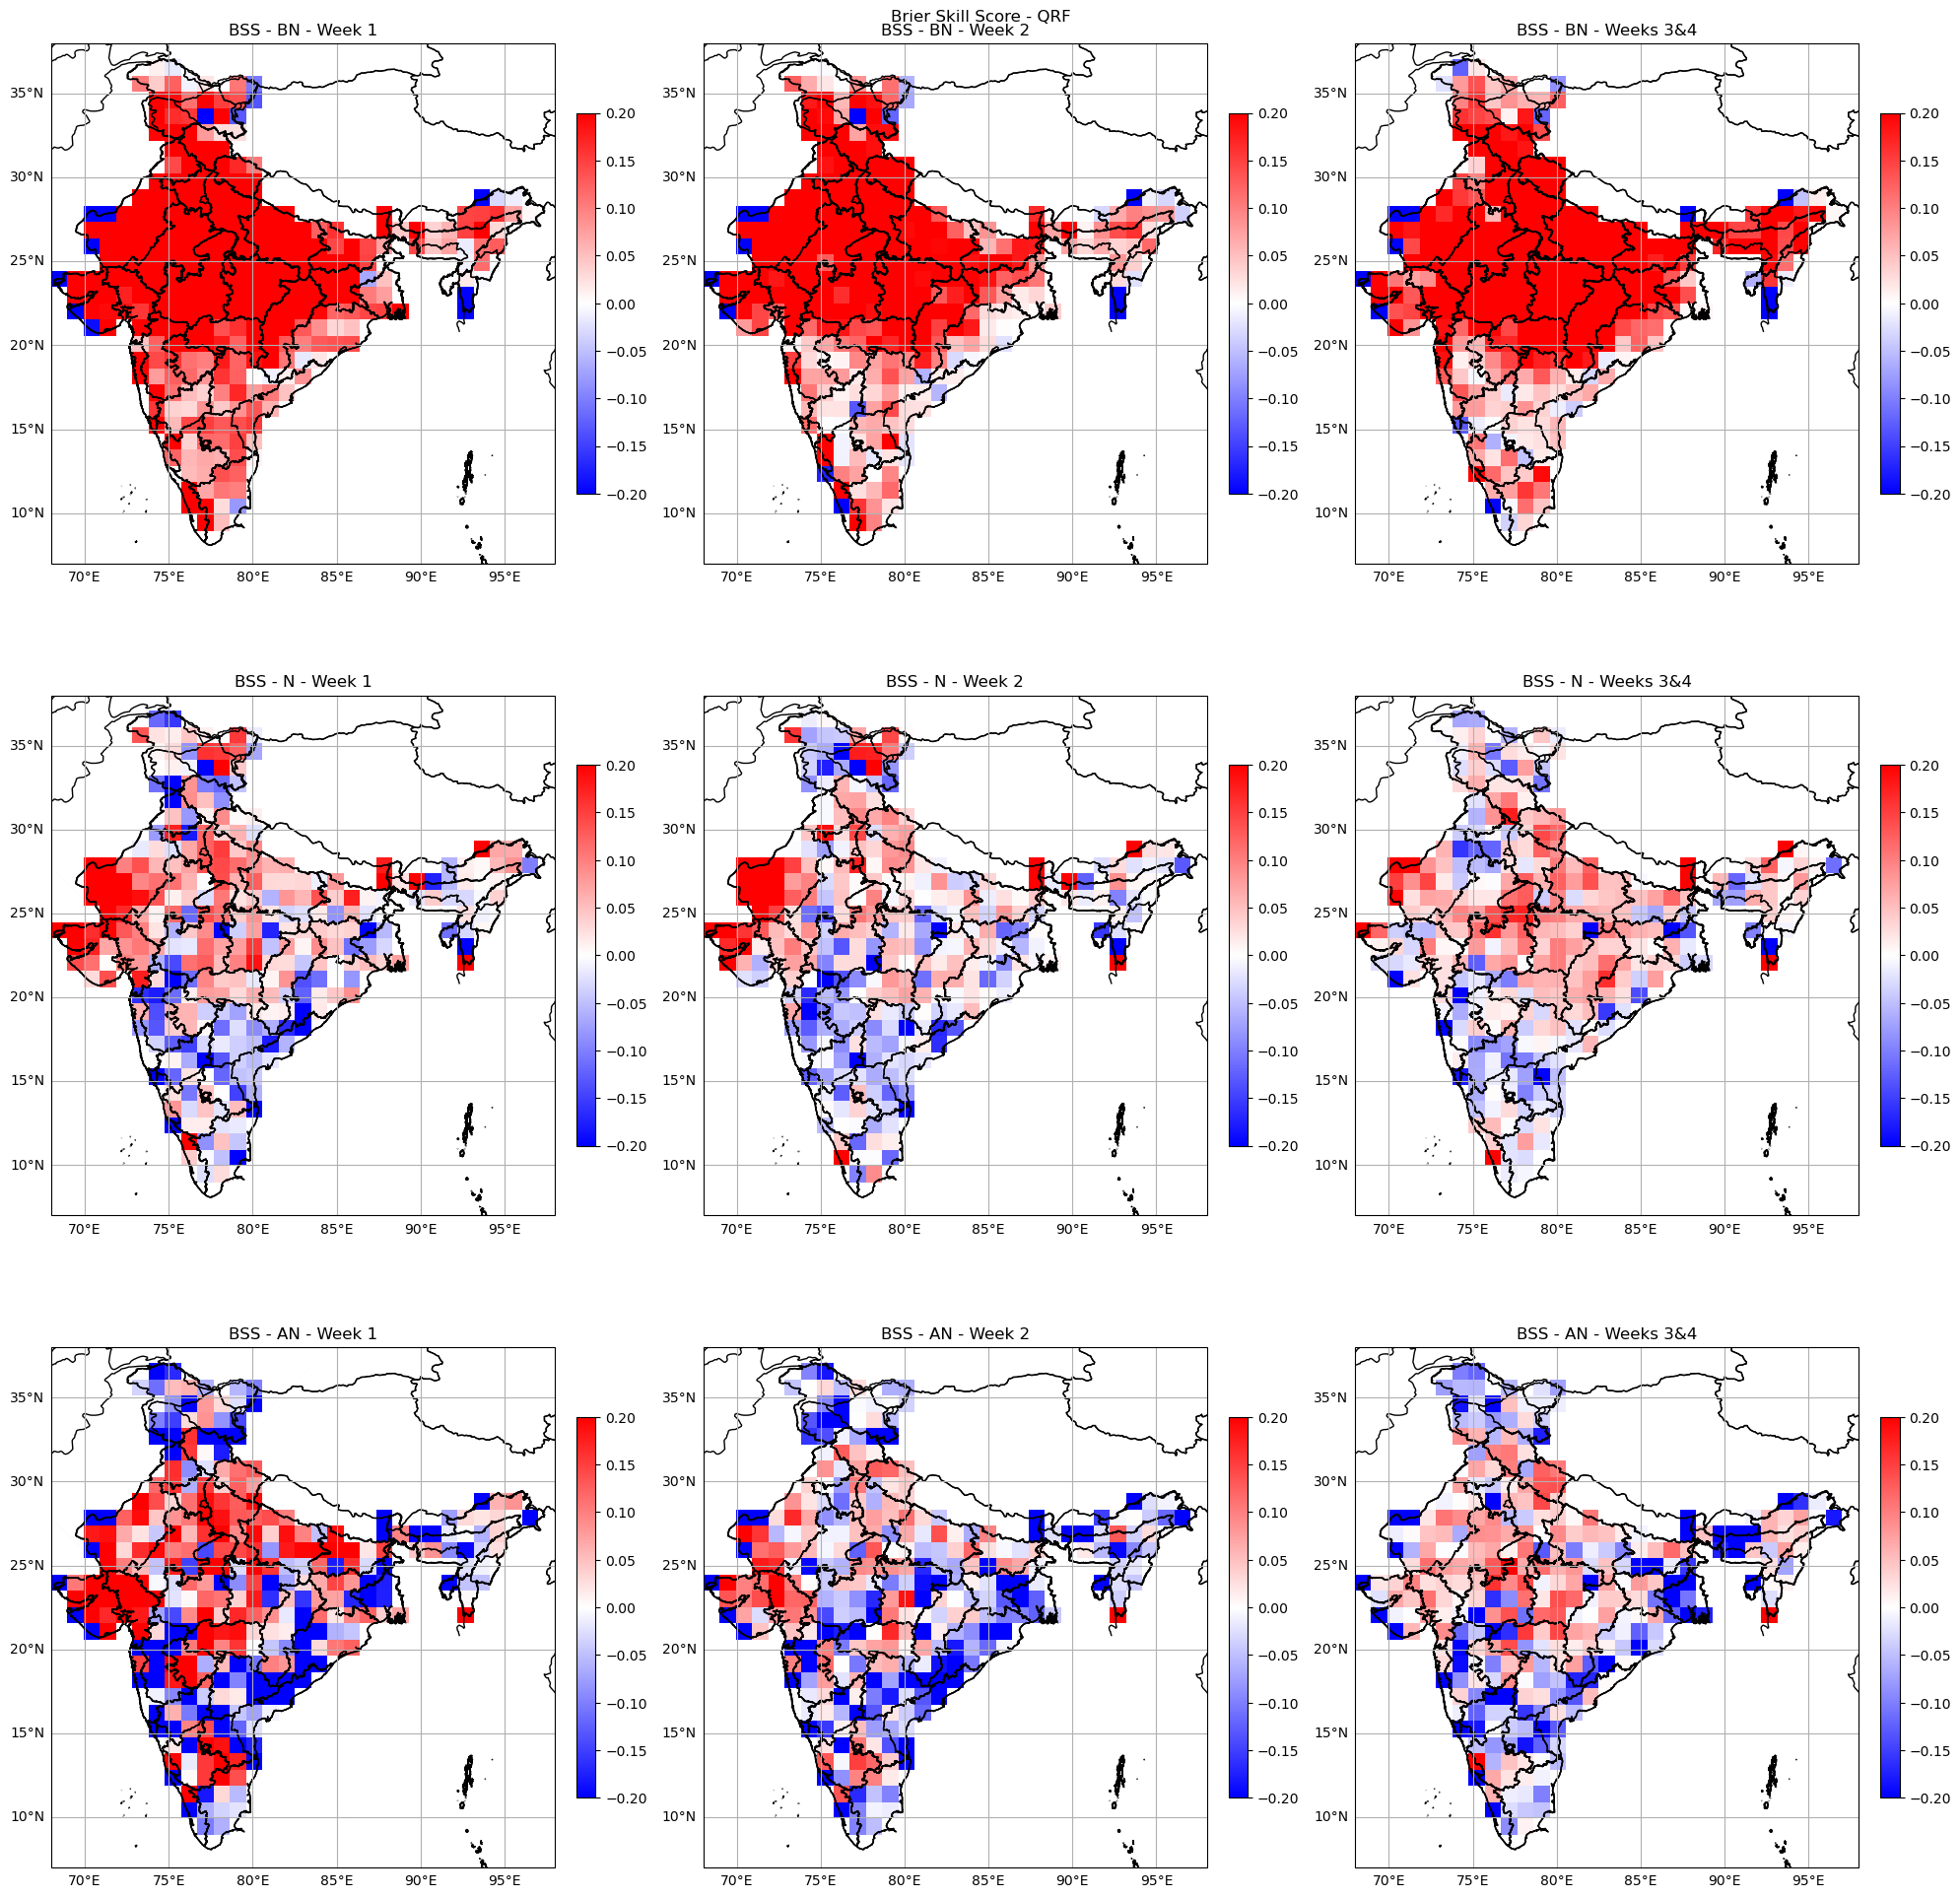

In [23]:
plot_rpss_rps(bss_1_bn, bss_2_bn, bss_34_bn, bss_1_n, bss_2_n, bss_34_n,
              bss_1_an, bss_2_an, bss_34_an, 
             save=True, title = 'Brier Skill Score - QRF')

In [24]:
bss_1_bn = np.load('./bss/bss_mat_elr_week_1_bn.npy')
bss_1_n = np.load('./bss/bss_mat_elr_week_1_n.npy')
bss_1_an = np.load('./bss/bss_mat_elr_week_1_an.npy')
                  
bss_2_bn = np.load('./bss/bss_mat_elr_week_2_bn.npy')
bss_2_n = np.load('./bss/bss_mat_elr_week_2_n.npy')
bss_2_an = np.load('./bss/bss_mat_elr_week_2_an.npy')

bss_34_bn = np.load('./bss/bss_mat_elr_week_34_bn.npy')
bss_34_n = np.load('./bss/bss_mat_elr_week_34_n.npy')
bss_34_an = np.load('./bss/bss_mat_elr_week_34_an.npy')

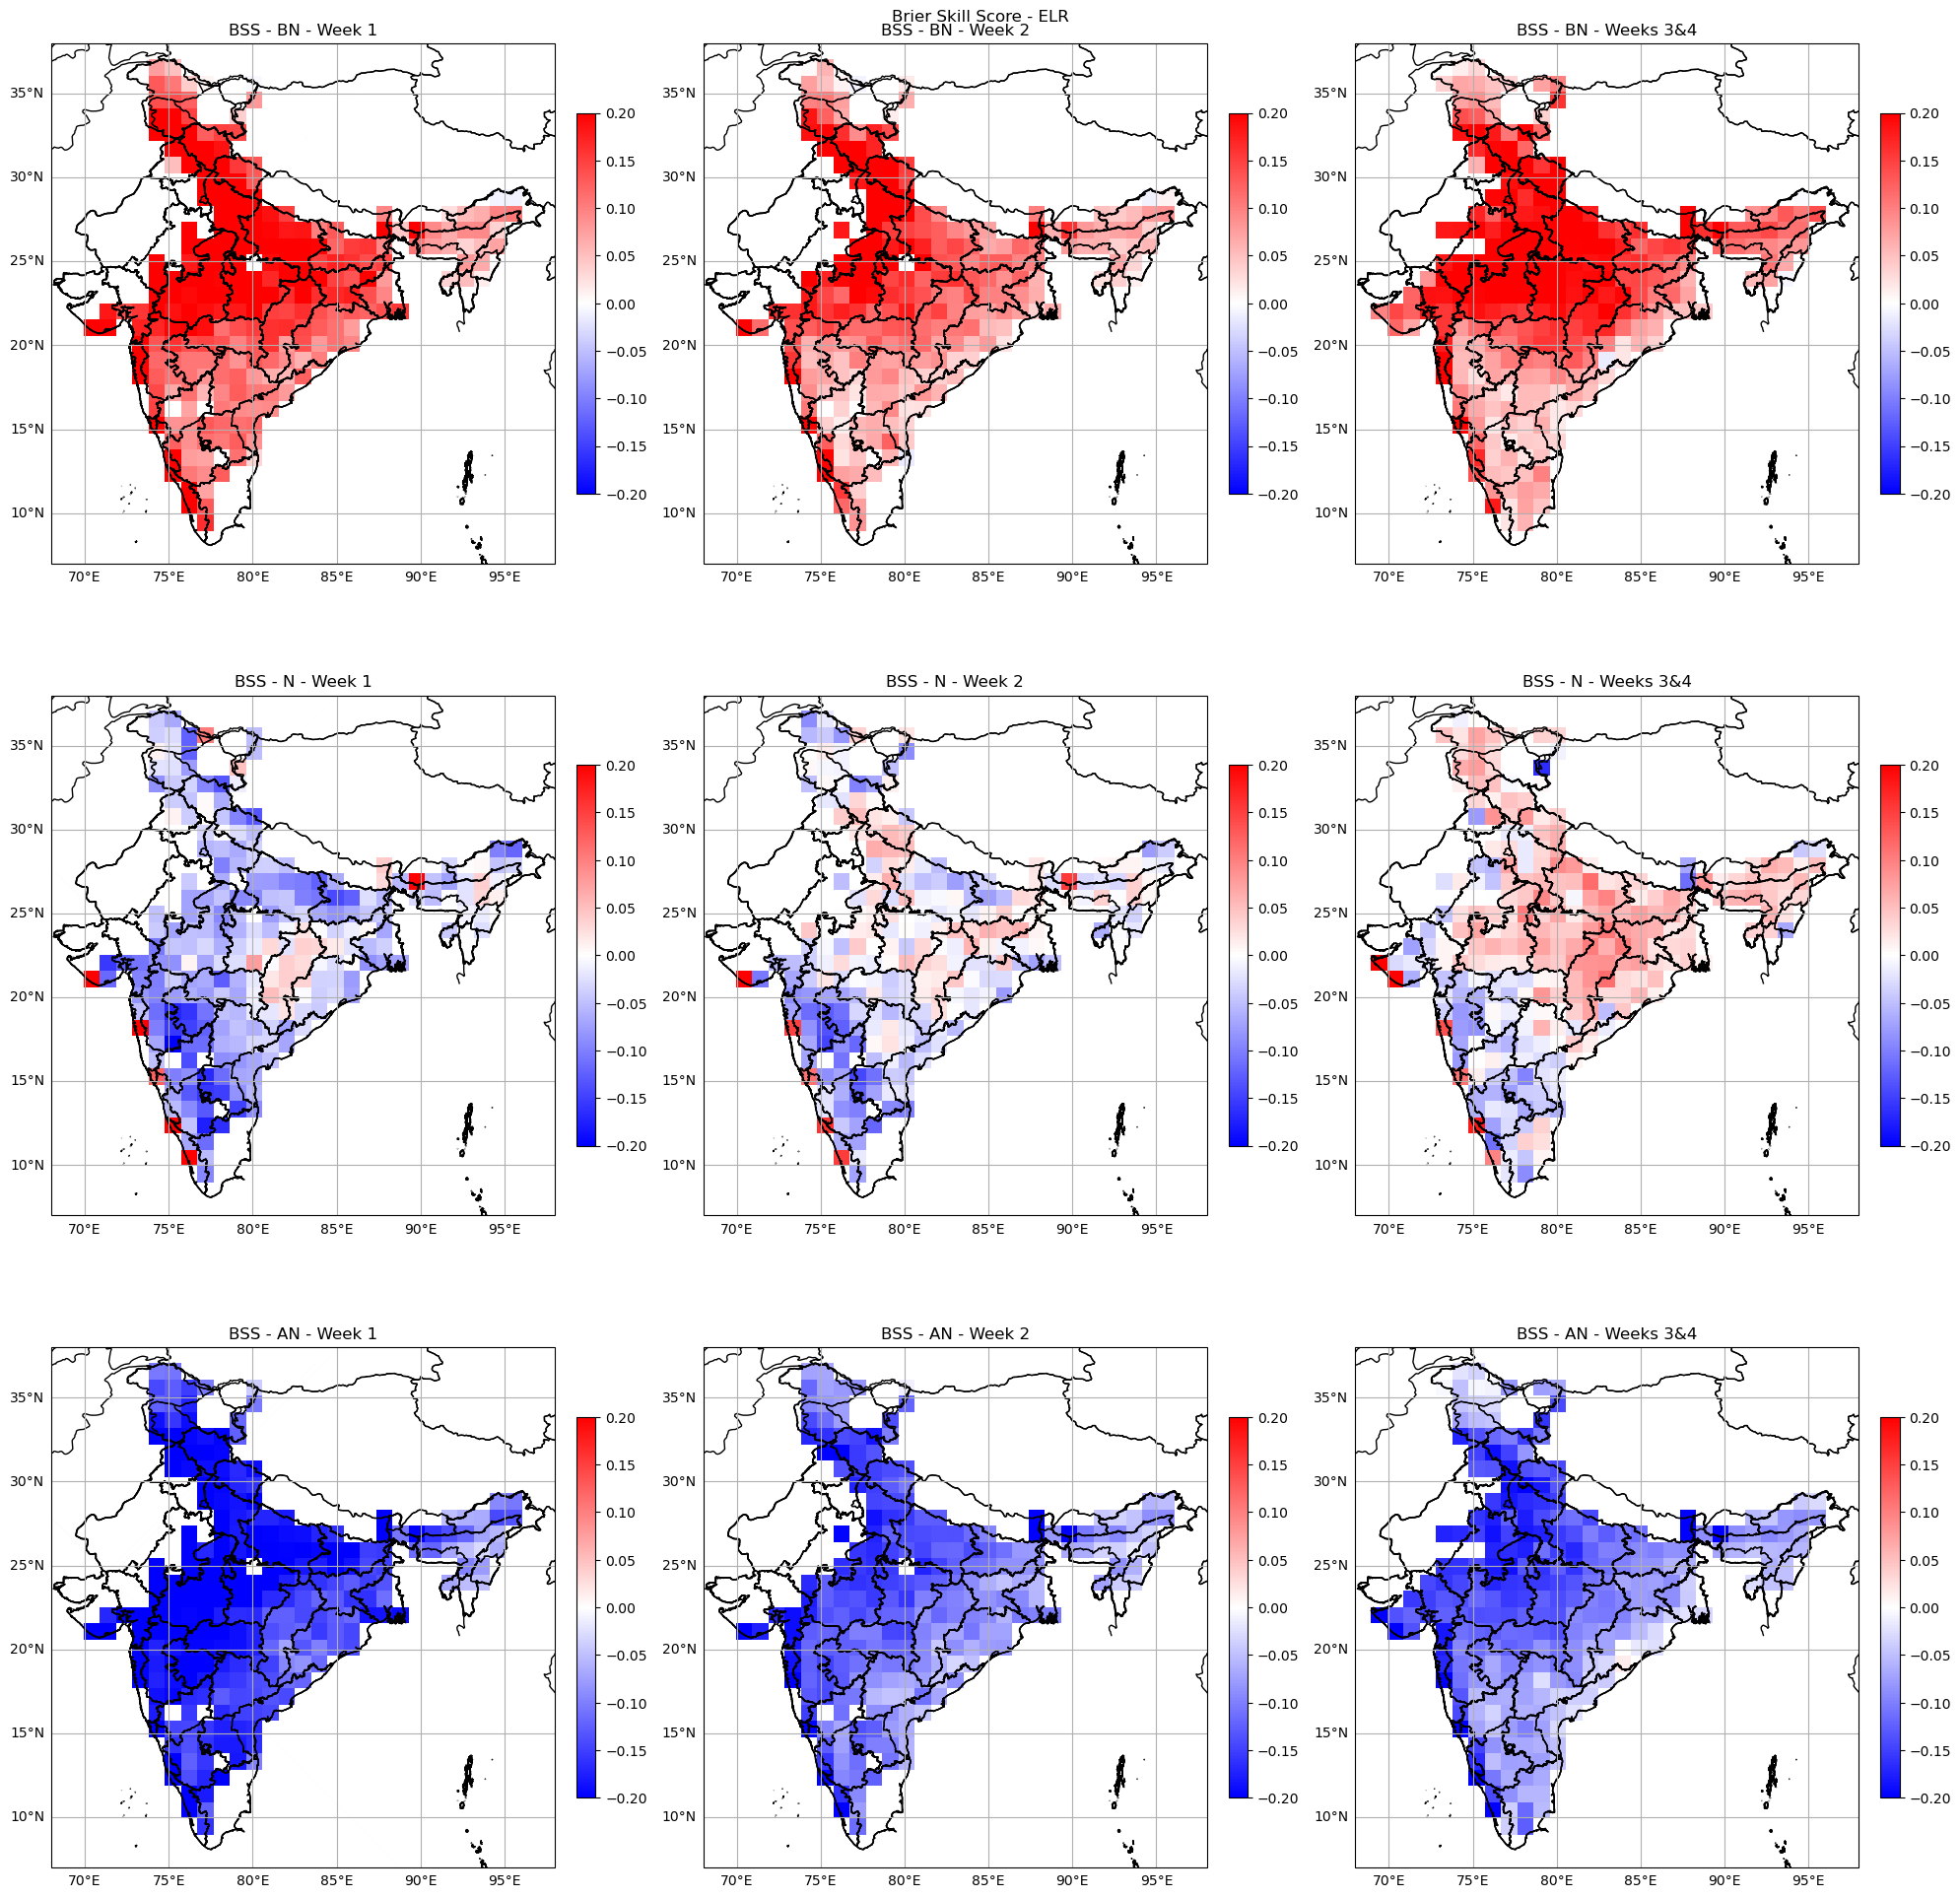

In [25]:
plot_rpss_rps(bss_1_bn, bss_2_bn, bss_34_bn, bss_1_n, bss_2_n, bss_34_n,
              bss_1_an, bss_2_an, bss_34_an, 
             save=True, title = 'Brier Skill Score - ELR')